<a href="https://colab.research.google.com/github/brunoortega/minicurso_sscad_2026/blob/main/GPUZIPy_Compare_CESM_NYX_Isabel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GPUZIPy: cuSZp × cuZFP × nvCOMP Bitcomp

Comparação de compressores em GPU usando o **GPUZIPy** (wrapper Python do GPUZIP) nos datasets **CESM-ATM**, **NYX** e **Hurricane Isabel** (SDRBench).

**Métricas:** PSNR, SSIM, throughput (compressão e descompressão, GB/s) e razão de compressão (CR).

**Como usar:** `Ambiente de execução → Alterar tipo de ambiente de execução → GPU` e depois `Executar tudo`.

> API do GPUZIPy conforme o notebook oficial de exemplo (`CompressorCuszp/ZFP/Bitcomp`, `compress`, `decompress`).

## 1. Instalação e GPU

In [ ]:
!nvidia-smi --query-gpu=name,compute_cap,memory.total --format=csv
!pip install -q gpuzipy --only-binary gpuzipy --find-links https://github.com/LSC-Unicamp/GPUZIP/releases/expanded_assets/2.1.0
!pip install -q cupy-cuda12x sdrbench huggingface_hub pandas matplotlib

name, compute_cap, memory.total [MiB]
Tesla T4, 7.5, 15360 MiB


In [ ]:
import time, os, inspect, gc
import numpy as np
import pandas as pd
import cupy as cp
import matplotlib.pyplot as plt
import gpuzipy

print("cupy:", cp.__version__, "| GPU:", cp.cuda.runtime.getDeviceProperties(0)["name"].decode())
print("gpuzipy:", getattr(gpuzipy, "__version__", "?"))
print([n for n in dir(gpuzipy) if not n.startswith("_")])

/usr/local/lib/python3.13/dist-packages/cupy/_environment.py:677: UserWarning: 
--------------------------------------------------------------------------------

  CuPy may not function correctly because multiple CuPy packages are installed
  in your environment:

    cupy-cuda12x, cupy-cuda13x

  Follow these steps to resolve this issue:

    1. For all packages listed above, run the following command to remove all
       existing CuPy installations:

         $ pip uninstall <package_name>

      If you previously installed CuPy via conda, also run the following:

         $ conda uninstall cupy

    2. Install the appropriate CuPy package.
       Refer to the Installation Guide for detailed instructions.

         https://docs.cupy.dev/en/stable/install.html

--------------------------------------------------------------------------------

  warnings.warn(f'''


cupy: 14.2.0 | GPU: Tesla T4
gpuzipy: 2.1.0
['Compressor', 'CompressorBitcomp', 'CompressorCuszp', 'CompressorZFP', 'compress', 'compressed_buffer_max_size', 'compressed_buffer_size', 'decompress']


## 2. Configuração do experimento

- **cuSZp:** limite de erro (relativo à faixa de valores → convertido em absoluto).
- **cuZFP:** taxa fixa (bits por valor), modo *fixed-rate*.
- **Bitcomp:** modo com *delta* estático (`bitcomp_delta_config = 2`), usando os **mesmos erros absolutos** do cuSZp para uma comparação justa.
- Cada configuração gera um ponto na curva taxa-distorção (CR × PSNR/SSIM).

In [ ]:
REL_EBS   = [1e-2, 1e-3, 1e-4]        # cuSZp e Bitcomp (erro absoluto = REL_EB * (max-min))
ZFP_RATES = [2, 4, 8, 12, 16]         # bits/valor (float32 = 32 bits -> CR = 32/rate)
WARMUP, REPS = 2, 5                   # repeticoes de cronometragem (mediana)
PSNR_TARGET = 60.0                    # dB, usado na tabela resumo "melhor CR com PSNR >= alvo"

DATASETS = {
    # nome: (dataset sdrbench, campo, shape esperado)
    "CESM-ATM":        dict(src="cesm-atm",         field="CLDHGH", shape=(1800, 3600)),
    "NYX":             dict(src="nyx",              field="temperature", shape=(512, 512, 512)),
    "Hurricane Isabel":dict(src="hurricane-isabel", field="P", step="07", shape=(100, 500, 500)),
}

### 2.1 Download dos dados (SDRBench)
Baixa **um único campo** de cada dataset (espelho no Hugging Face via pacote `sdrbench`) — não os arquivos `.tar.gz` inteiros. Se preferir outro campo, edite `DATASETS`.

In [ ]:
import sdrbench
from pathlib import Path

def _to_array(obj, shape):
    if isinstance(obj, (str, Path)):
        obj = np.fromfile(obj, dtype="<f4")
    arr = np.asarray(obj)
    if arr.size != int(np.prod(shape)):
        raise ValueError(f"tamanho inesperado {arr.size} != {int(np.prod(shape))} para shape {shape}")
    return np.ascontiguousarray(arr.reshape(shape).astype(np.float32, copy=False))

def load_dataset(cfg):
    if cfg["src"] == "hurricane-isabel":
        ds = sdrbench.dataset("hurricane-isabel", cfg["field"])
        obj = ds[cfg["field"], cfg["step"]]
    else:
        obj = sdrbench.load(cfg["src"], cfg["field"])
    return _to_array(obj, cfg["shape"])

DATA = {}
for name, cfg in DATASETS.items():
    try:
        DATA[name] = load_dataset(cfg)
    except Exception as e:
        print(f"[{name}] falha no sdrbench ({e!r}).")
        print(f"   -> envie o arquivo .f32 para o Colab e use: DATA['{name}'] = _to_array('/content/arquivo.f32', {cfg['shape']})")
for k, v in DATA.items():
    print(f"{k:18s} shape={v.shape} dtype={v.dtype} min={v.min():.4g} max={v.max():.4g} finite={np.isfinite(v).all()} ({v.nbytes/1e6:.0f} MB)")

1800x3600/CLDHGH_1_1800_3600.f32: reconstructing file:   0%|          |  0.00B / 25.9MB            

1800x3600/CLDHGH_1_1800_3600.f32: downloading bytes:           |  0.00B            

512x512x512/temperature.f32: reconstructing file:   0%|          |  0.00B /  537MB            

512x512x512/temperature.f32: downloading bytes:           |  0.00B            

Pf/Pf07.f32: reconstructing file:   0%|          |  0.00B /  100MB            

Pf/Pf07.f32: downloading bytes:           |  0.00B            

CESM-ATM           shape=(1800, 3600) dtype=float32 min=0.001636 max=0.8956 finite=True (26 MB)
NYX                shape=(512, 512, 512) dtype=float32 min=2281 max=4.783e+06 finite=True (537 MB)
Hurricane Isabel   shape=(100, 500, 500) dtype=float32 min=-4698 max=2262 finite=True (100 MB)


## 3. Camada de acesso ao GPUZIPy

API conforme o notebook de exemplo oficial: um objeto `Compressor*` por (shape, parâmetro) e as funções de módulo `compress(comp, ptr_src, ptr_dst)` (retorna o tamanho comprimido em bytes) e `decompress(comp, ptr_src, ptr_dst)`, sempre com ponteiros de device do CuPy.

In [ ]:
from gpuzipy import (CompressorBitcomp, CompressorZFP, CompressorCuszp,
                     compress, decompress, compressed_buffer_max_size)

def _shape3(shape):
    # GPUZIP espera 3 dimensões; campos 2D (CESM-ATM) viram (1, H, W)
    s = tuple(int(i) for i in shape)
    return (1,) * (3 - len(s)) + s

def build_cuszp(shape, x, eb_abs):
    n1, n2, n3 = _shape3(shape)
    return CompressorCuszp(n1, n2, n3, float(eb_abs))

def build_zfp(shape, x, rate):
    n1, n2, n3 = _shape3(shape)
    return CompressorZFP(n1, n2, n3, 'float', rate)

def build_bitcomp(shape, x, delta):
    n1, n2, n3 = _shape3(shape)
    return CompressorBitcomp(n1, n2, n3, 2, 0.0, 0.0, float(delta), 'float', 'default')  # 2 = STATIC_DELTA

BUILDERS = {"cuSZp": build_cuszp, "cuZFP": build_zfp, "Bitcomp": build_bitcomp}

def params_for(kind, vrange):
    if kind == "cuZFP":
        return [(f"rate={r}", r) for r in ZFP_RATES]
    return [(f"eb={e:g}", e * vrange) for e in REL_EBS]   # erro absoluto = rel * (max-min)

## 4. Métricas (PSNR, SSIM na GPU)

In [ ]:
from cupyx.scipy.ndimage import uniform_filter

def _slabs(n0, step):
    for s in range(0, n0, step):
        yield s, min(s + step, n0)

def psnr_gpu(a, b, vrange, step=64):
    sse, cnt = 0.0, 0
    for s, e in _slabs(a.shape[0], step):
        d = a[s:e].astype(cp.float64) - b[s:e].astype(cp.float64)
        sse += float((d * d).sum()); cnt += d.size
    mse = sse / cnt
    return float("inf") if mse == 0 else 20 * np.log10(vrange) - 10 * np.log10(mse)

def ssim_gpu(a, b, vrange, win=7, step=64):
    # SSIM médio (janela uniforme 7, K1=0.01, K2=0.03, como o padrão do skimage), calculado em slabs com halo.
    # Dados normalizados por (x - min)/range para reduzir cancelamento numérico.
    mn = float(a.min()); pad = (win - 1) // 2
    C1, C2 = 0.01 ** 2, 0.03 ** 2
    n0 = a.shape[0]; total, count = 0.0, 0
    for s, e in _slabs(n0, step):
        lo, hi = max(0, s - pad), min(n0, e + pad)
        x = (a[lo:hi].astype(cp.float64) - mn) / vrange
        y = (b[lo:hi].astype(cp.float64) - mn) / vrange
        f = lambda t: uniform_filter(t, size=win, mode="reflect")
        mx, my = f(x), f(y)
        vx, vy, cxy = f(x * x) - mx * mx, f(y * y) - my * my, f(x * y) - mx * my
        m = ((2 * mx * my + C1) * (2 * cxy + C2)) / ((mx * mx + my * my + C1) * (vx + vy + C2))
        # região válida: sem as bordas de pad em todos os eixos
        r0, r1 = max(s, pad), min(e, n0 - pad)
        if r1 <= r0: continue
        sl = (slice(r0 - lo, r1 - lo),) + (slice(pad, -pad),) * (a.ndim - 1)
        v = m[sl]; total += float(v.sum()); count += v.size
    return total / count

## 5. Benchmark

Para cada (dataset × compressor × parâmetro): aquecimento, `REPS` medições com `cudaEvent`, mediana de tempo → throughput em **GB/s sobre o tamanho original** (convenção usual em compressão com perdas). A CR é `bytes_originais / bytes_comprimidos` usando o tamanho retornado por `Compress`.

In [ ]:
def time_gpu(fn, reps):
    ts = []
    for _ in range(reps):
        a, b = cp.cuda.Event(), cp.cuda.Event()
        a.record(); fn(); b.record(); b.synchronize()
        ts.append(cp.cuda.get_elapsed_time(a, b) / 1e3)   # s
    return float(np.median(ts))

def run_case(ds_name, kind, label, param, x, vrange):
    nbytes = x.nbytes
    shp = _shape3(x.shape)
    xs = x.reshape(shp)
    comp = BUILDERS[kind](x.shape, x, param)
    cbuf = cp.cuda.malloc_async(int(compressed_buffer_max_size(comp)))
    out = cp.empty(shp, dtype=cp.float32)
    size = [0]
    def c(): size[0] = int(compress(comp, xs.data.ptr, cbuf.ptr))
    def d(): decompress(comp, cbuf.ptr, out.data.ptr)
    for _ in range(WARMUP): c(); d()
    cp.cuda.Stream.null.synchronize()
    tc = time_gpu(c, REPS); td = time_gpu(d, REPS)
    c(); d(); cp.cuda.Stream.null.synchronize()
    row = dict(dataset=ds_name, compressor=kind, config=label,
               cr=nbytes / size[0], comp_GBps=nbytes / tc / 1e9, decomp_GBps=nbytes / td / 1e9,
               psnr=psnr_gpu(xs, out, vrange), ssim=ssim_gpu(x, out.reshape(x.shape), vrange))
    del comp, cbuf, out, xs; cp.get_default_memory_pool().free_all_blocks()
    return row

rows = []
for ds_name, arr in DATA.items():
    x = cp.asarray(arr); vrange = float(x.max() - x.min())
    for kind in BUILDERS:
        for label, p in params_for(kind, vrange):
            try:
                r = run_case(ds_name, kind, label, p, x, vrange); rows.append(r)
                print(f"{ds_name:17s} {kind:8s} {label:10s} CR={r['cr']:7.2f} PSNR={r['psnr']:6.2f} SSIM={r['ssim']:.4f} "
                      f"C={r['comp_GBps']:6.1f} D={r['decomp_GBps']:6.1f} GB/s")
            except Exception as e:
                print(f"{ds_name:17s} {kind:8s} {label:10s} FALHOU: {type(e).__name__}: {str(e)[:300]}")
    del x; cp.get_default_memory_pool().free_all_blocks()

df = pd.DataFrame(rows)
df.to_csv("gpuzipy_benchmark.csv", index=False)
df

CESM-ATM          cuSZp    eb=0.01    CR=   5.90 PSNR= 28.59 SSIM=0.9658 C=  30.6 D=  52.6 GB/s
CESM-ATM          cuSZp    eb=0.001   CR=   3.69 PSNR= 28.70 SSIM=0.9924 C=  19.9 D=  31.0 GB/s
CESM-ATM          cuSZp    eb=0.0001  CR=   2.67 PSNR= 28.70 SSIM=0.9927 C=  18.2 D=  30.6 GB/s
CESM-ATM          cuZFP    rate=2     CR=   4.00 PSNR= 45.10 SSIM=0.9797 C=  14.0 D=  19.4 GB/s
CESM-ATM          cuZFP    rate=4     CR=   2.00 PSNR= 62.29 SSIM=0.9995 C=   7.4 D=  13.4 GB/s
CESM-ATM          cuZFP    rate=8     CR=   1.00 PSNR= 91.84 SSIM=1.0000 C=   4.9 D=  22.8 GB/s
CESM-ATM          cuZFP    rate=12    CR=   0.67 PSNR=120.92 SSIM=1.0000 C=   9.0 D=  20.1 GB/s
CESM-ATM          cuZFP    rate=16    CR=   0.50 PSNR=149.82 SSIM=1.0000 C=   9.6 D=  18.3 GB/s
CESM-ATM          Bitcomp  eb=0.01    CR=  10.62 PSNR= 50.79 SSIM=0.9925 C= 137.8 D= 122.9 GB/s
CESM-ATM          Bitcomp  eb=0.001   CR=   5.14 PSNR= 70.79 SSIM=0.9999 C= 128.9 D= 114.8 GB/s
CESM-ATM          Bitcomp  eb=0.0001  CR

,dataset,compressor,config,cr,comp_GBps,decomp_GBps,psnr,ssim
0,CESM-ATM,cuSZp,eb=0.01,5.895867,30.587968,52.638420,28.592529,0.965810
1,CESM-ATM,cuSZp,eb=0.001,3.688716,19.865601,31.021409,28.698004,0.992392
2,CESM-ATM,cuSZp,eb=0.0001,2.665477,18.208794,30.644673,28.699123,0.992694
3,CESM-ATM,cuZFP,rate=2,3.999985,14.046162,19.398875,45.104974,0.979713
4,CESM-ATM,cuZFP,rate=4,1.999996,7.367052,13.393743,62.290530,0.999536
5,CESM-ATM,cuZFP,rate=8,0.999999,4.947502,22.776481,91.838277,0.999999
6,CESM-ATM,cuZFP,rate=12,0.666666,8.995203,20.063907,120.918258,1.000000
7,CESM-ATM,cuZFP,rate=16,0.500000,9.601593,18.316261,149.821339,1.000000
8,CESM-ATM,Bitcomp,eb=0.01,10.618181,137.755100,122.876215,50.791041,0.992465
9,CESM-ATM,Bitcomp,eb=0.001,5.138628,128.898793,114.844748,70.791281,0.999922


## 6. Resultados

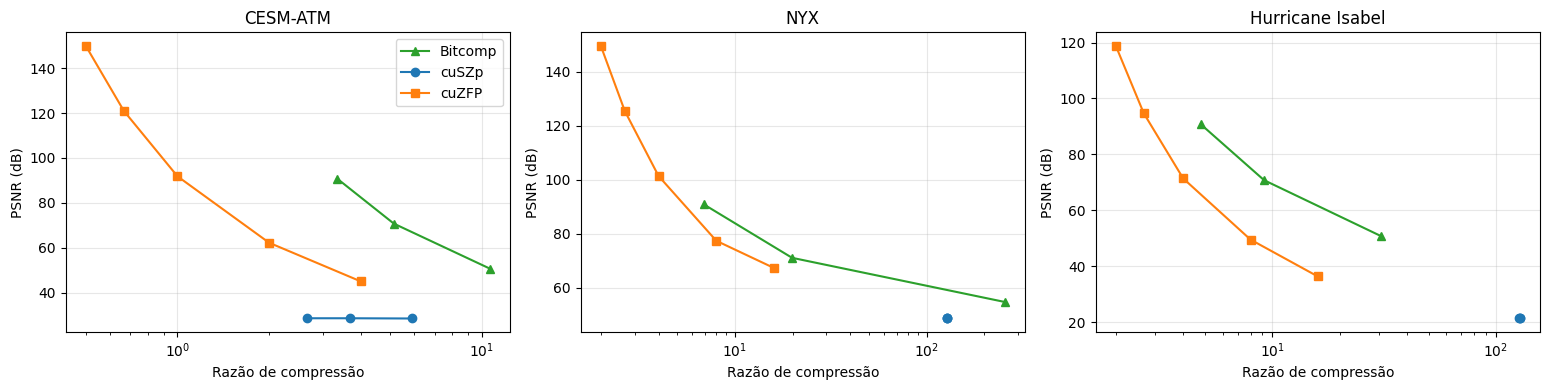

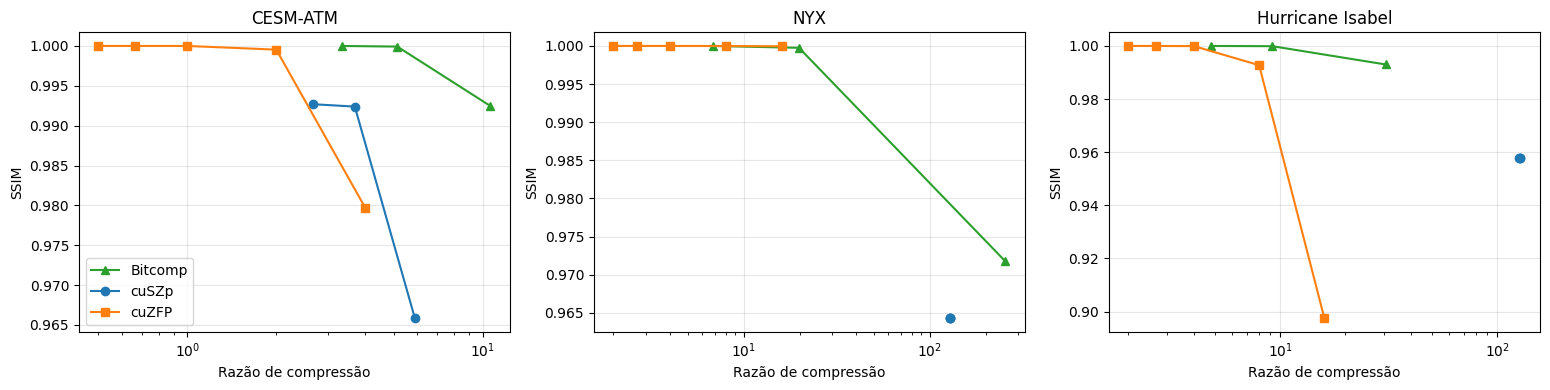

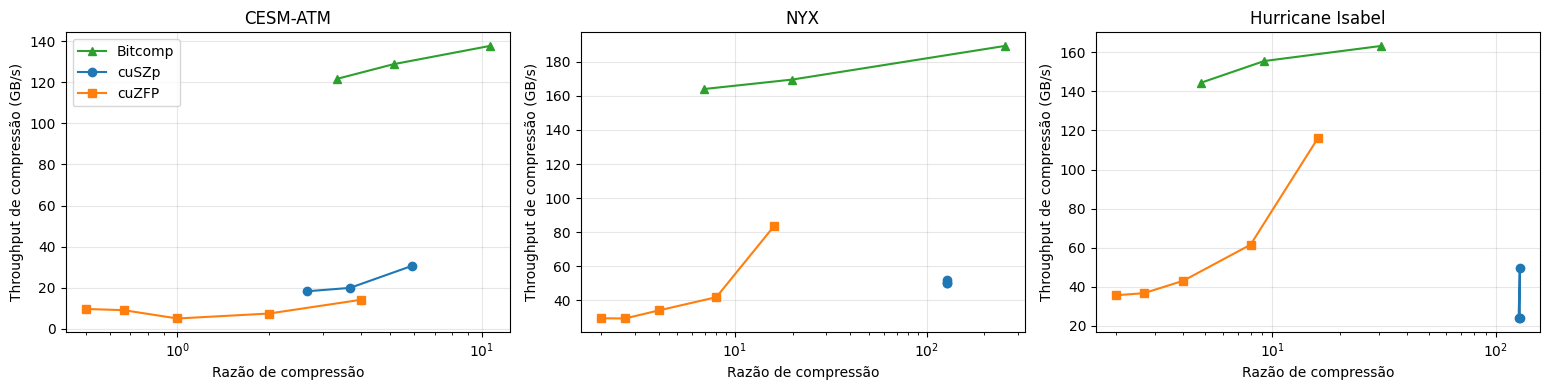

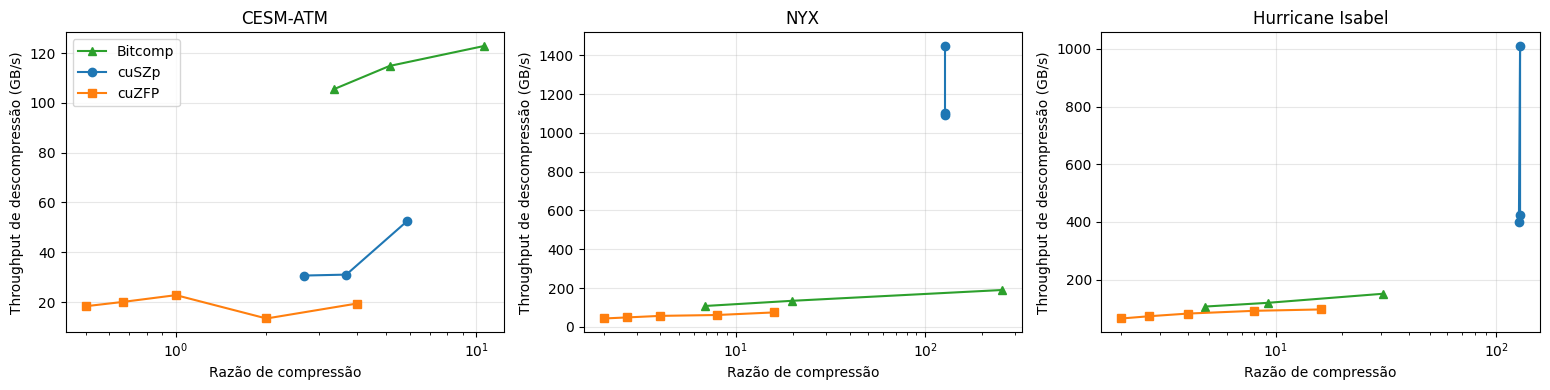

In [ ]:
COLORS = {"cuSZp": "tab:blue", "cuZFP": "tab:orange", "Bitcomp": "tab:green"}
MARK   = {"cuSZp": "o", "cuZFP": "s", "Bitcomp": "^"}

def grid(ycol, ylabel, xcol="cr", xlabel="Razão de compressão", logx=True, fname=None):
    names = list(DATA)
    fig, axs = plt.subplots(1, len(names), figsize=(5.2 * len(names), 4), squeeze=False)
    for ax, n in zip(axs[0], names):
        for k, g in df[df.dataset == n].groupby("compressor"):
            g = g.sort_values(xcol)
            ax.plot(g[xcol], g[ycol], marker=MARK[k], color=COLORS[k], label=k)
        ax.set_title(n); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.grid(alpha=.3)
        if logx: ax.set_xscale("log")
    axs[0][0].legend(); plt.tight_layout()
    if fname: plt.savefig(fname, dpi=150)
    plt.show()

grid("psnr", "PSNR (dB)", fname="psnr_vs_cr.png")
grid("ssim", "SSIM", fname="ssim_vs_cr.png")
grid("comp_GBps", "Throughput de compressão (GB/s)", fname="comp_throughput_vs_cr.png")
grid("decomp_GBps", "Throughput de descompressão (GB/s)", fname="decomp_throughput_vs_cr.png")

In [ ]:
# Tabela completa por dataset
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
for n, g in df.groupby("dataset"):
    print(f"\n=== {n} ===")
    display(g.drop(columns="dataset").sort_values(["compressor", "cr"]).reset_index(drop=True))

# Resumo: melhor CR que ainda atinge PSNR >= PSNR_TARGET
best = (df[df.psnr >= PSNR_TARGET].sort_values("cr", ascending=False)
          .groupby(["dataset", "compressor"], as_index=False).first())
print(f"\nMelhor CR com PSNR >= {PSNR_TARGET} dB:")
display(best[["dataset", "compressor", "config", "cr", "psnr", "ssim", "comp_GBps", "decomp_GBps"]])


=== CESM-ATM ===


,compressor,config,cr,comp_GBps,decomp_GBps,psnr,ssim
0,Bitcomp,eb=0.0001,3.348,121.750,105.469,90.790,1.000
1,Bitcomp,eb=0.001,5.139,128.899,114.845,70.791,1.000
2,Bitcomp,eb=0.01,10.618,137.755,122.876,50.791,0.992
3,cuSZp,eb=0.0001,2.665,18.209,30.645,28.699,0.993
4,cuSZp,eb=0.001,3.689,19.866,31.021,28.698,0.992
5,cuSZp,eb=0.01,5.896,30.588,52.638,28.593,0.966
6,cuZFP,rate=16,0.500,9.602,18.316,149.821,1.000
7,cuZFP,rate=12,0.667,8.995,20.064,120.918,1.000
8,cuZFP,rate=8,1.000,4.948,22.776,91.838,1.000
9,cuZFP,rate=4,2.000,7.367,13.394,62.291,1.000



=== Hurricane Isabel ===


,compressor,config,cr,comp_GBps,decomp_GBps,psnr,ssim
0,Bitcomp,eb=0.0001,4.789,144.388,106.173,90.811,1.000
1,Bitcomp,eb=0.001,9.202,155.527,119.084,70.801,1.000
2,Bitcomp,eb=0.01,30.626,163.245,150.552,50.842,0.993
3,cuSZp,eb=0.0001,126.448,24.032,399.565,21.378,0.958
4,cuSZp,eb=0.01,127.990,49.442,"1,010.019",21.378,0.958
5,cuSZp,eb=0.001,127.990,23.830,423.040,21.378,0.958
6,cuZFP,rate=16,2.000,35.711,64.759,118.769,1.000
7,cuZFP,rate=12,2.667,36.784,72.553,94.694,1.000
8,cuZFP,rate=8,4.000,43.121,81.834,71.432,1.000
9,cuZFP,rate=4,8.000,61.584,91.396,49.576,0.993



=== NYX ===


,compressor,config,cr,comp_GBps,decomp_GBps,psnr,ssim
0,Bitcomp,eb=0.0001,6.895,164.040,107.753,90.792,1.000
1,Bitcomp,eb=0.001,19.876,169.587,134.433,71.032,1.000
2,Bitcomp,eb=0.01,255.644,189.340,190.112,54.682,0.972
3,cuSZp,eb=0.01,128.000,52.180,"1,448.309",48.567,0.964
4,cuSZp,eb=0.001,128.000,50.035,"1,101.301",48.567,0.964
5,cuSZp,eb=0.0001,128.000,50.156,"1,092.978",48.567,0.964
6,cuZFP,rate=16,2.000,29.414,43.193,149.472,1.000
7,cuZFP,rate=12,2.667,29.278,48.744,125.393,1.000
8,cuZFP,rate=8,4.000,33.998,56.731,101.312,1.000
9,cuZFP,rate=4,8.000,41.783,61.269,77.339,1.000



Melhor CR com PSNR >= 60.0 dB:


,dataset,compressor,config,cr,psnr,ssim,comp_GBps,decomp_GBps
0,CESM-ATM,Bitcomp,eb=0.001,5.139,70.791,1.000,128.899,114.845
1,CESM-ATM,cuZFP,rate=4,2.000,62.291,1.000,7.367,13.394
2,Hurricane Isabel,Bitcomp,eb=0.001,9.202,70.801,1.000,155.527,119.084
3,Hurricane Isabel,cuZFP,rate=8,4.000,71.432,1.000,43.121,81.834
4,NYX,Bitcomp,eb=0.001,19.876,71.032,1.000,169.587,134.433
5,NYX,cuZFP,rate=2,16.000,67.255,1.000,83.512,74.649


## 7. Como interpretar

- **Compare em PSNR igual, não em parâmetro igual**: `eb` (cuSZp/Bitcomp) e `rate` (cuZFP) não são a mesma coisa; as curvas CR×PSNR e CR×SSIM são a comparação justa.
- **cuZFP** (taxa fixa) tem CR previsível (32/rate) e qualidade variável; **cuSZp** garante erro máximo; **Bitcomp** com delta é um esquema de quantização + empacotamento rápido, em geral com CR menor mas throughput alto.
- Throughput é medido só no kernel de compressão/descompressão (sem transferência host↔device), em GB/s sobre o tamanho **original**.
- Para outros campos, troque `field` em `DATASETS` (ex.: `baryon_density` no NYX, `QCLOUD` no Hurricane, `PRECT` no CESM-ATM).

**Referências:** [GPUZIP](https://github.com/LSC-Unicamp/GPUZIP) · [SDRBench](https://sdrbench.github.io/)